# **Machine Learning Project: Part 2**
## *Random Forest & ElasticNet on adapted CropNet Dataset*

### Table of Contents

1. [Introduction](#introduction)
2. [Handeling missing values](#missing-val)
3. [Remove Features](#remove)
4. [Nested Cross-Validation](#cross-val)
5. [Model selection and evaluation](#models)
    - [Dummy Regressor](#dummy)
    - [Random Forest Regressor](#rf)
    - [Elastic Net](#elastic-net)
6. [Discussion of results](#discussion)

## **Introduction**<a id="intro"></a>

The project focuses on corn yeild prediction in the US in 2020. The dataset is based on the CropNet Dataset which is a constructed from ... TODO

The features in the dataset can be divided into 4 parts:
1. the general information of the county: the counties FIPS code, county name, state that the county is in and the year,
2. the weather data features for each month of the year,
3. the Sentinel-2 derived features for each month of the year,
4. the ground truth yield lables obtained through the USDA dataset;

**Machine learning task:** Our task is a regression task, based on the weather and sentinel-2 derived data we want to predict our continous target varible: the corn yeild per county in the US in 2020. 

This part of the project is focused on chooseing, training and evaluating the performance of two machine learning algorithms and comparig their results. 

We decided to choos for our task the Random Forest Regressor and the Elastic Net. 

**Random Forest** is an ensemble model which trains multiple rCART models and averaging their result.

**Elastic Net** is a linear regression model that can use two types of regularization to minimalize overfitting.

We decided to go with these two models to explore the possibilities of two different model families (linear and ensemble), and compare the ease of use of each one of them. 

In [56]:
import pandas as pd
pd.set_option('display.max_colwidth', None)
import matplotlib.pyplot as plt
import numpy as np

RANDOM_STATE = 52

In [57]:
path = "data.csv"
df = pd.read_csv(path)

display(df.describe(include='all'))

print(f"Number of samples: {len(df)}")

,Unnamed: 0,fips,county,state,year,yield_bu_acre,jan_temp_mean_k,jan_temp_std_k,jan_temp_max_k,jan_temp_min_k,...,mar_s2_days_since_latest,apr_s2_days_since_latest,may_s2_days_since_latest,jun_s2_days_since_latest,jul_s2_days_since_latest,aug_s2_days_since_latest,sep_s2_days_since_latest,oct_s2_days_since_latest,nov_s2_days_since_latest,dec_s2_days_since_latest
count,1601.000000,1601.000000,1601,1601,1601.0,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000,...,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000,1601.000000
unique,NaN,NaN,1005,30,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,WASHINGTON,IL,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,18,99,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,800.000000,28905.316677,NaN,NaN,2020.0,154.926921,274.951898,4.905296,289.144264,260.746704,...,14.620862,7.262961,7.090568,7.199250,4.762648,6.007495,5.019988,5.536540,5.177389,10.540912
std,462.313206,12436.152538,NaN,NaN,0.0,35.974390,5.992475,0.981472,6.623779,7.826905,...,14.682917,10.657576,10.881575,6.720186,5.074064,5.439434,5.371299,7.003576,5.553581,11.169198
min,0.000000,1001.000000,NaN,NaN,2020.0,22.800000,261.097124,2.011532,272.139963,239.876552,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,400.000000,19111.000000,NaN,NaN,2020.0,132.100000,271.356127,4.404308,285.665750,256.204294,...,2.000000,1.000000,1.000000,2.000000,1.000000,3.000000,1.000000,0.000000,2.000000,4.000000
50%,800.000000,28033.000000,NaN,NaN,2020.0,161.300000,274.571112,4.886299,290.211917,261.888917,...,7.000000,3.000000,2.000000,5.000000,3.000000,5.000000,4.000000,2.000000,3.000000,5.000000
75%,1200.000000,39061.000000,NaN,NaN,2020.0,182.200000,279.151465,5.418277,293.723893,266.200000,...,24.000000,9.000000,8.000000,11.000000,7.000000,8.000000,8.000000,9.000000,7.000000,17.000000


Number of samples: 1601


In the final dataset we have 1601 samples and 317 features and the ground truth corn yeild.

The features and their descriptions are presented in the table below:

Feature Name | Description 
----------------------------------- | -------------------------
`fips` |  Unique identifier of the county in question
`county` | County name
`state` | Abbreviation of State name
`year` | Year (in our case 2020)
`yield_bu_acre` | Yearly yield for the county in bushels per acre
`{month}_temp_mean_k` | Mean monthly temperature in Kelvin
`{month}_temp_std_k` | Monthly standard deviation of the temperature in Kelvin
`{month}_temp_max_k` | Maximum temperature recorded in a given month in Kelvin
`{month}_temp_min_k` | Minimum temperature recorded in a given month in Kelvin
`{month}_precip_mean_mm` | Mean precipitation for a given month in milimiters
`{month}_precip_std_mm` | Monthly standard deviation of precipitation in milimiters
`{month}_rh_mean_pct` | Monthly mean relative humidity in %
`{month}_rh_std_pct` | Monthly standard deviation in relative humidity in %
`{month}_gust_mean_m_s` | Monthly mean gust speed in m/s
`{month}_gust_std_m_s` | Montlhy standard deviation of gust speed in m/s
`{month}_wind_mean_m_s` | Monthly average of the wind speed in a given county in m/s
`{month}_wind_std_m_s` | Standard deviation of the wind seed in a given month in m/s
`{month}_wind_u_mean_m_s` | Mean horizontal wind speed moving towards the East in m/s 
`{month}_wind_u_std_m_s` | Standard deviation of the horizontal wind speed moving towards the East in m/s 
`{month}_wind_v_mean_m_s`| Mean horizontal wind speed moving towards the North in m/s 
`{month}_wind_v_std_m_s`| Standard deviation of the horizontal wind speed moving towards the North in m/s 
`{month}_srad_mean_w_m2`| Monthly mean shortwave radiation the reaches the Earth in W/m2
`{month}_srad_std_w_m2`| Standard deviation of the shortwave radiation the reaches the Earth in W/m2
`{month}_vpd_mean_kpa`| Mean Vapor Pressure Deficit in kPa
`{month}_vpd_std_kpa` | Standard deviation of the monthly Vapor Pressure Deficit in kPa
`{month}_area_km2` | Total county area covered, km² 
`{month}_crop_area_km2`  | Area classified as cropland in that month, km² 
`{month}_mean_crop_ndvi` | Mean NDVI over cropland pixels (NaN when crop area is 0) 
`{month}_crop_ndvi_per_km2` | `mean_crop_ndvi × crop_area_km2 / area_km2`, i.e. crop NDVI weighted by crop share of the county 
`{month}_cloud_area_km2` | Cloud-covered area, km² 
`{month}_cloud_per_km2` | `cloud_area_km2 / area_km2`, i.e. cloud fraction 

With the code in the cell above we checked that most of the features are numerical, only descriptive features like the county name or state abbriveation are of type string. 

We can then set our target column to `"yield_bu_acre"` and define the descrptive columns.


In [58]:
target_label = "yield_bu_acre"
non_numeric_labels = ["fips", "county", "state", "year"]
groups = df["state"]

## **Handeling of Missing values**<a id="missing-val"></a>

In [59]:
# explore the data in regards to no-data values 
missing_values_col_list = []
for col in df.columns:
    sum_nan = df[col].isna().sum()
    if sum_nan != 0:
        print(f'{col}: {sum_nan}')
        missing_values_col_list.append(col)
print(missing_values_col_list)

jan_ndvi_crop_mean: 116
feb_ndvi_crop_mean: 61
mar_ndvi_crop_mean: 14
oct_ndvi_crop_mean: 2
dec_ndvi_crop_mean: 32
['jan_ndvi_crop_mean', 'feb_ndvi_crop_mean', 'mar_ndvi_crop_mean', 'oct_ndvi_crop_mean', 'dec_ndvi_crop_mean']


We can see that all of the no-data values fall in the '{month}_ndvi_crop_mean' variable. 

This fact comes from the definitio of this perticular feature. The ndvi_crop_mean feature was calculated by dividing the sum of ndvi over the crop region by the crop area obtaied from Dynamic World (DW). 

The months in which the problem occures are Jnuary, February, March, October and December, which are especially cloudy in the northen hemisfere. They could be also considered as winter months when crop fields don't ocurre too often. 

For those resons the DW masks for thouse months might have either been cloudy or if in a perticular month in a perticular county the crop area was equal to 0 then the division was impossible and the value is set to nan. 

Because we could identify this problem and we know the porpuse of it we can fill the no-data values with 0 as there is no crop in this pertcular case. 

In [60]:
# filling the no-data values with 0
df = df.fillna(0)

## **Remove Features**<a id="remove"></a>

The table below summarises which feature (columns) we decided to remove and why. 

| Features | Columns | Count | Reason |
|---|---|---|---|
| Cloud cover | `{month}_cloud_per_km2`, `{month}_cloud_area_km2` | 24 | 99.6% of values are ~0, and have almost no information. |
| Duplicate county area | `feb_area_km2` … `dec_area_km2` | 11 | County area is the same every month, so 11 columns are duplicates. |
| Winter Sentinel-2 features | `{dec,jan,feb,mar}_{crop_area_km2, ndvi_crop_mean, ndvi_crop_per_km2, s2_days_since_latest}` | 16 | 8–13% of counties have no new Sentinel-2 image in these months. |
| Metadata | `fips`, `county`, `state`, `year` | 4 | These aren't predictive features. |

Refer to the docstrings in the `code` block below for more information on the removal of each respective feature.

Removing redundant / uninformative features early is important for our selected models:
1. Random forests will take longer to train when there are more features (as each split has to be evaluated for each feature).
2. TODO: elastic net too...
4. TODO: talk about how s2 features are in fact poor features...



=== Remove non numeric features ===
Removing non-numeric features...
NUM FEATURES: 330 -> 326

=== Remove duplicate area features ===
County area does not change month-to-month.
Removing all {m}_area_km2 except for one...
NUM FEATURES: 326 -> 315

=== Remove cloud features ===
Percentage Cloud Cover > 0.20: 0.0004
Percentage Cloud Cover < 0.001: 0.9959
Removing Dynamic World cloud / cloud shadow features...
NUM FEATURES: 315 -> 291

=== Remove redundant s2 months ===
Removing monthly s2 features that have counties with image acquisition from previous months...
Removing {m}_s2_days_since_latest as no longer needed...
NUM FEATURES: 291 -> 267


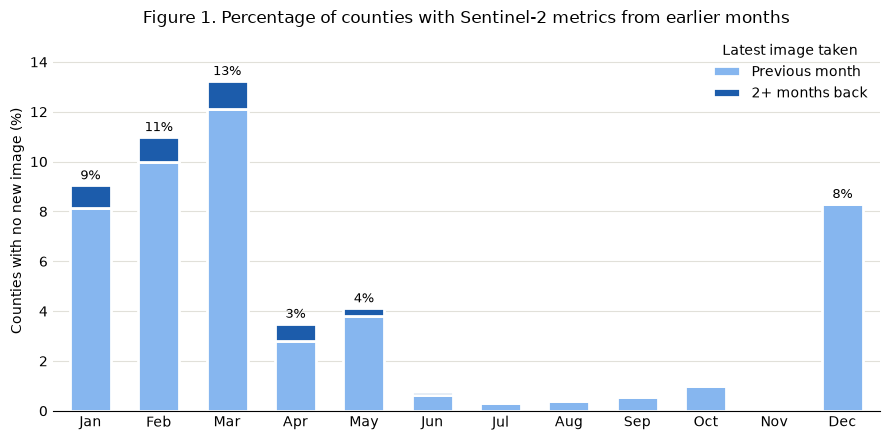

In [61]:
import functools


MONTHS = [
   'jan', 'feb', 'mar', 'apr',
   'may', 'jun', 'jul', 'aug',
   'sep', 'oct', 'nov', 'dec'
]


def log_feat_selection(func):
    @functools.wraps(func)
    def wrapper(df, *args, **kwargs):
        print(f"\n=== {func.__name__.replace("_", " ").capitalize()} ===")
        result = func(df, *args, **kwargs)
        print(f"NUM FEATURES: {df.shape[1]} -> {result.shape[1]}")
        return result
    return wrapper


@log_feat_selection
def remove_non_numeric_features(df, non_numeric_labels):
   print("Removing non-numeric features...")
   return df.drop(non_numeric_labels, axis=1)


@log_feat_selection
def remove_duplicate_area_features(df):
   """Remove redundant area features.
   
   The data processing notebook calculated the area of a county for 
   each month of the year. Of course, the area of a county does not change 
   month-to-month, so we can drop 11 of these 12 features.
   """
   area_columns = [f"{m}_area_km2" for m in MONTHS]
   print(f"County area does not change month-to-month.")
   print("Removing all {m}_area_km2 except for one...")

   df = df.rename(columns={"jan_area_km2": "area_km2"})
   return df.drop(area_columns[1:], axis=1)


@log_feat_selection
def remove_cloud_features(df):
   """Remove uninformative cloud statistics.

   The data processing notebook filters images using ESA's cloud mask.
   It filters out images with cloud cover greater than 20.0%. As a sanity check,
   we then calculated statistics using Dynamic World cloud / cloud shadow mask.

   The ESA cloud mask filter effectively removed all images with cloud,
   so these statistics are mostly 0.0, hence why we are removing these features.
   """
   cloud_frac_columns = [f"{m}_cloud_per_km2" for m in MONTHS]
   total_gt_20 = (df[cloud_frac_columns] > 0.20).sum().sum()
   total_eq_0 = (df[cloud_frac_columns] < 0.001).sum().sum()

   print(f"Percentage Cloud Cover > 0.20: {total_gt_20/(len(df)*len(MONTHS)):.4f}")
   print(f"Percentage Cloud Cover < 0.001: {total_eq_0/(len(df)*len(MONTHS)):.4f}")
   print("Removing Dynamic World cloud / cloud shadow features...")

   cloud_columns = cloud_frac_columns + [f"{m}_cloud_area_km2" for m in MONTHS]
   return df.drop(cloud_columns, axis=1)


@log_feat_selection
def remove_redundant_s2_months(df):
   """Remove s2 image features for months with no cloud-free image acquisition.

   As a result of the cloud filtering (in the processing notebook), some months
   end up with images from the previous month (and sometimes the month before that!).
   These features are then, of course, very correlated, as they share the same data.

   We found that the months dec - mar suffer from this problem most (the cloudy months),
   and so we drop the S2 features for those months. These are, conveniently, not
   growing months for corn and are likely safe to remove.

   NOTE: this problem plagues the original CropNet dataset too (as they acquire S2 
         images the same way), but they fail to mention or account for this in their
         paper.
   """
   _plot_stale_images(pd.read_csv(path))
   months_to_drop = ["dec", "jan", "feb", "mar"]
   s2_features = ["crop_area_km2", "ndvi_crop_mean", "ndvi_crop_per_km2"]
   s2_columns = [f"{m}_{f}" for m in months_to_drop for f in s2_features]
   print("Removing monthly s2 features that have counties with image acquisition from previous months...")
   df = df.drop(s2_columns, axis=1)

   # we also delete this s2_days_since_latest features, as they were 
   # simply used to identify problematic S2 month features per county.
   days_since_latest_column = [f"{m}_s2_days_since_latest" for m in MONTHS]
   print("Removing {m}_s2_days_since_latest as no longer needed...")
   return df.drop(days_since_latest_column, axis=1)



def _plot_stale_images(df, year=2020, min_label=1):
   """TODO: AI DISCLAIMER
   """
   ends = pd.date_range(f"{year}-01-01", periods=12, freq="ME")
   back = pd.DataFrame({
      m: e.month + 12 * (e.year - d.dt.year) - d.dt.month
      for m, e in zip(MONTHS, ends)
      for d in [e - pd.to_timedelta(df[f"{m}_s2_days_since_latest"], unit="D")]
   })
   pct = pd.DataFrame({"Previous month": (back == 1).mean(), "2+ months back": (back >= 2).mean()}) * 100
   total = pct.sum(axis=1)
   ax = pct.rename(index=str.capitalize).plot.bar(stacked=True, rot=0, width=0.6, figsize=(9, 4.5),
                                                color=["#86b6ef", "#1c5cab"], edgecolor="white", lw=2)
   ax.bar_label(ax.containers[-1], [f"{v:.0f}%" if v >= min_label else "" for v in total], fontsize=9, padding=2)
   ax.spines[["top", "right", "left"]].set_visible(False)
   ax.grid(axis="y", color="#e1e0d9"); ax.set_axisbelow(True); ax.tick_params(length=0)
   ax.set(ylabel="Counties with no new image (%)", ylim=(0, total.max() * 1.15))
   ax.set_title("Figure 1. Percentage of counties with Sentinel-2 metrics from earlier months")
   ax.legend(frameon=False, title="Latest image taken")
   plt.tight_layout()
   return ax

df = remove_non_numeric_features(df, non_numeric_labels)
df = remove_duplicate_area_features(df)
df = remove_cloud_features(df)
df = remove_redundant_s2_months(df)

plt.show()

**Figure 1**: In the processing notebook, Sentinel-2 images for a month are taken by looking 180 days back 
from the end of the target month (e.g. Jan 31st). The most recent image is used as that month's image (identical to the CropNet dataset).
Some counties are completely cloudy in certain months, so the image for that month can come from a previous month (e.g. Dec or even Nov).
The figure shows the percentage of counties with no Sentinel-2 image acquisition in the target month.

# TODO: present the methodology and its justification.

## **Nested Cross-Validation**<a id="cross-val"></a>

As mentioned in the introduction our dataset consists of 1601 samples. To our knowleage a dataset of this size should be considered as a small dataset, because of that a decision was made to use **nested cross-validation** to get the generalization performance of our models. The nested cross-validation will let us tune the hyperparameters of our models as well as test their generalization performacne against multiple train/test splits without any data leakage between thouse two processes.

The strategy choosen for the cross-validation is the **Stratified Group K-Folds** with 5 outer folds (keeping the test dataset at ~20% of the dataset) and 4 inner folds.

As our dataset is definetaly spatial we needed to devide it into regions. The regions (or groups for the Group K-Folds) are set as the US states, as the corn yeild within them presents spatial autocorrelation. The stratification in our strategy comes form the fact that we want to have a dataset for training, validation and testing in each fold that would mirror the true distribution of our target variable. 
As our target varaible is a continous one we needed to create artificial bins to be sampled form for the stratified sampling. We decided to go with 5 equal-interval bins to keep the homogeninty within the stratum (assumption of stratified sampling) as well as let each stratum be representable in each of the folds (bigger number of bins would prevent that). 

As presented in figure 2, the Stratified Group K-Fold chooses the initial groups (or the US states) to set asside for testing in the outer loop (the groups are choosesn in a way that agrees with the stratification) and then the remaining groups are split into train and validation within the inner folds.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

Y_BINS = 5
OUTER_SPLITS = 5
INNER_SPLITS = 4

X = df.drop(columns=target_label)
y = df[target_label]
outer_cv = StratifiedGroupKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# using the equal-interval binning to keep homogeneity within the stratum
y_bin = pd.cut(y, Y_BINS, labels=False)

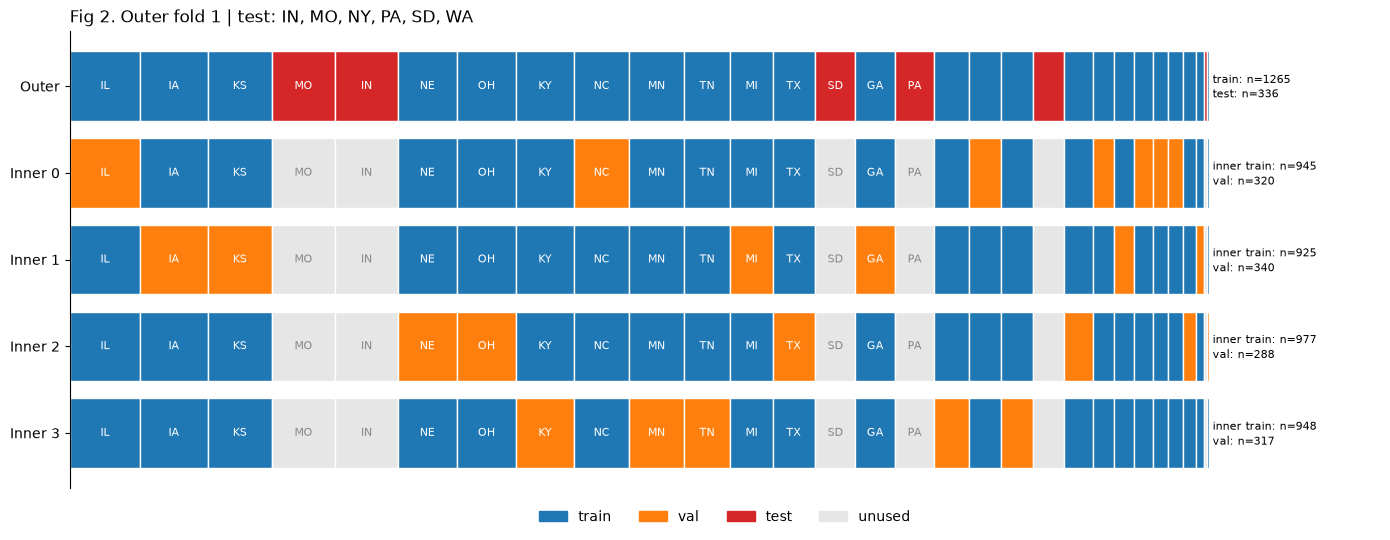

In [88]:
# TODO: AI DISCLAIMER

from matplotlib.patches import Patch

COLORS = {"train": "#1f77b4", "val": "#ff7f0e", "test": "#d62728", "unused": "#e6e6e6"}

def plot_outer_fold(outer_idx, y_bin, groups, outer_cv, inner_cv):
    """Plot one outer fold and its inner splits, one block per group."""
    y, groups = np.asarray(y_bin), np.asarray(groups)
    X_dummy = np.zeros(len(y))                      # splitters only need the length
    order = pd.Series(groups).value_counts()        # largest group first

    train_idx, test_idx = list(outer_cv.split(X_dummy, y, groups))[outer_idx]

    # One role per sample for each row of the plot
    outer = np.where(np.isin(np.arange(len(y)), test_idx), "test", "train")
    rows = [("Outer", outer)]
    for k, (itr, iva) in enumerate(inner_cv.split(X_dummy[train_idx], y[train_idx], groups[train_idx])):
        roles = np.full(len(y), "unused", dtype=object)
        roles[train_idx[itr]] = "train"             # map back to original positions
        roles[train_idx[iva]] = "val"
        rows.append((f"Inner {k}", roles))

    fig, ax = plt.subplots(figsize=(14, 0.8 * len(rows) + 1.5))
    for r, (label, roles) in enumerate(rows):
        left = 0
        for g, size in order.items():
            role = roles[groups == g][0]            # a group never spans two roles
            ax.barh(r, size, left=left, color=COLORS[role], edgecolor="white")
            if size / len(y) >= 0.03:
                ax.text(left + size / 2, r, g, ha="center", va="center", fontsize=8,
                        color="#888" if role == "unused" else "white")
            left += size

        n_train = (roles == "train").sum()
        if label == "Outer":
            text = f"train: n={n_train}\ntest: n={(roles == 'test').sum()}"
        else:
            text = f"inner train: n={n_train}\nval: n={(roles == 'val').sum()}"
        ax.text(left + 5, r, text, va="center", fontsize=8, linespacing=1.3)

    ax.set_xlim(0, len(y) * 1.15)                   # leave room for the labels
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows])
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.set_title(f"Fig 2. Outer fold {outer_idx} | test: {', '.join(sorted(set(groups[test_idx])))}", loc="left")
    ax.legend(handles=[Patch(color=c, label=k) for k, c in COLORS.items()],
              ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False)
    fig.tight_layout()
    return fig

plot_outer_fold(1, y_bin, groups, outer_cv, inner_cv)
plt.show()

**Figure 2:** Presents the train, validation and test sets selected for an outer and all inner folds of our stratified group k-folds cross-validation strategy. As states are our grouping measure if a state is choosen for the test set (red) then the counties from this state are compleatly eliminated from further sampling.  

## **Model selection**<a id="models"></a>

In [95]:
import time

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

NUM_TREES_START = 10
NUM_TREES_STEP = 10
MAX_TREES = 1000

def tune_num_trees(estimator, X_train, y_train, inner_splits):
    results = {}
    for inner_fold, (inner_train_idx, val_idx) in enumerate(inner_splits):
        X_inner_train, X_val = X_train.iloc[inner_train_idx], X_train.iloc[val_idx]
        y_inner_train, y_val = y_train.iloc[inner_train_idx], y_train.iloc[val_idx]

        accuracies = []
        rf = clone(estimator).set_params(randomforestregressor__warm_start=True)
        for n in range(NUM_TREES_START, MAX_TREES+1, NUM_TREES_STEP):
            rf.set_params(randomforestregressor__n_estimators=n)
            rf.fit(X_inner_train, y_inner_train)   # add one tree
            score = r2_score(y_val, rf.predict(X_val))
            accuracies.append(score)

        results[inner_fold] = accuracies

    results_df = pd.DataFrame(results)

    n_trees = np.arange(NUM_TREES_START, MAX_TREES, NUM_TREES_STEP)
    avg_scores = results_df.mean(axis=1).to_numpy()
    avg_scores_se = avg_scores.std() / np.sqrt(len(avg_scores))

    best_idx = np.argmax(avg_scores)
    lower_bound = avg_scores[best_idx] - avg_scores_se
    chosen_n = n_trees[np.argmax(avg_scores >= lower_bound)]

    plot_num_trees(results_df, n_trees, chosen_n, se=avg_scores_se)
    plt.show()

    return chosen_n



def plot_num_trees(results_df, n_trees, chosen_n, se=None):
    mean = results_df.mean(axis=1).to_numpy()
    std = results_df.std(axis=1).to_numpy()
    best = np.argmax(mean)
    chosen = list(n_trees).index(chosen_n)
 
    plt.figure(figsize=(8, 5))
    plt.plot(n_trees, results_df, color="lightgray", lw=1)
    plt.fill_between(n_trees, mean - std, mean + std, alpha=0.15, label="±1 std")
    plt.plot(n_trees, mean, lw=2, label="Mean score")
    if se is not None:
        plt.axhline(mean[best] - se, color="gray", ls=":", label="Best − 1 SE")
 
    plt.axvline(n_trees[best], color="red", ls="--", alpha=0.5)
    plt.axvline(chosen_n, color="green", ls="--", alpha=0.5)
    plt.plot(n_trees[best], mean[best], "o", color="red", ms=8, mec="white",
             label=f"Best: {n_trees[best]} trees ({mean[best]:.3f})")
    plt.plot(chosen_n, mean[chosen], "o", color="green", ms=8, mec="white",
             label=f"Chosen: {chosen_n} trees ({mean[chosen]:.3f})")
 
    plt.title("Validation score vs. number of trees")
    plt.xlabel("Number of trees")
    plt.ylabel("Validation R²")
    plt.legend(loc="lower right", frameon=False)
    plt.grid(alpha=0.3)
    plt.gca().spines[["top", "right"]].set_visible(False)


# TODO: tune number of trees is a practical decision that we need to document, because searching the grid with 1000 trees is not that efficient. 
def evaluate_model(model, X, y, y_bin, groups, outer_cv, inner_cv):
    """
    """
    rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y_bin, groups)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        estimator, grid = model
        inner_splits = list(inner_cv.split(X_train, y_bin.iloc[train_idx], groups.iloc[train_idx]))

        if estimator.steps[-1][0] == "randomforestregressor":
            num_trees = tune_num_trees(estimator, X_train, y_train, inner_splits)
            estimator.set_params(randomforestregressor__n_estimators=num_trees)

        scoring = "neg_root_mean_squared_error"
        # clone(...) ensures that the model parameters of the estimator are not updated.
        # GridSearchCV returns an instance of a fitted estimator.
        search = GridSearchCV(clone(estimator), grid, cv=inner_splits, scoring=scoring, n_jobs=-1)

        t0 = time.perf_counter()
        final_model = search.fit(X_train, y_train)
        fit_time = time.perf_counter() - t0

        train_error = final_model.predict(X_train)

        t0 = time.perf_counter()
        pred = final_model.predict(X_test)
        predict_time = time.perf_counter() - t0

        rows.append({
            "fold": fold,
            "best_params": final_model.best_params_,
            "test_error_mae": mean_absolute_error(y_train, train_error),
            "test_error_rmse": root_mean_squared_error(y_train, train_error),
            "test_error_r2": r2_score(y_train, train_error),
            "mae": mean_absolute_error(y_test, pred),
            "rmse": root_mean_squared_error(y_test, pred),
            "r2": r2_score(y_test, pred),
            "fit_time": fit_time,
            "predict_time": predict_time,
        })

    return pd.DataFrame(rows)

# TODO: the only assertion that we're making is that if you use this grid search approach with these params you can expect a generalisation error in this range.

### Feature selection within the pipelines:
We decided it woud be interesting to include a custom feture selection algorithm within the model pipelines to check weather the models performace would be highly dependant on the numbr of features it's working with.

The custom feature selector has two options either it keeps the features for the entire year (so all months form January to December) or only considers the features which months correspond to the growing seson of corn (from april till october).

In [90]:
from sklearn.base import BaseEstimator, TransformerMixin

class SesonalFeatureSelector(BaseEstimator, TransformerMixin):
    """This custom feature selector depending on the setting 
    either keeps all of the features for the entire year or 
    selects features that are connected to the growing seson 
    of corn (april to october).

    Parameters
    ==============
    time_period: str or None
    the time period of the features of interest 
     - for the growing season features the "growing_season" 
    option should be selected. 
     - any other str value or None are equal to all year 
     features for corn.

    fit(X, y=None)
    =================
    Check the columns of X.

    transform(X)
    =================
    Reduce X to the selected feature columns.

    Implemented based on: 
    https://medium.com/@benjybo7/3-steps-to-implement-a-custom-feature-selector-in-python-116f114e15ad
    """
    def __init__(self, time_period=None):
        self.time_period = time_period


    def fit(self, X, y=None):
        self.columns_ = X.columns
        return self

    def transform(self, X):
        if self.time_period == "growing_season":
            months = ("jan", "feb", "mar", "nov", "dec")
            col_list = [col for col in self.columns_ if col.startswith(months)]
            X_dropped = X.drop(columns=col_list)
            return X_dropped
        else:
            return X


## **Dummy regressor**<a id="dummy"></a>

The dummy regressor is a model that assigns the same value to the prediction, in our case this prediction is going to be the mean value of the yeild.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline

dummy = (
            make_pipeline(SesonalFeatureSelector(), DummyRegressor()),
            {
                "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
                "dummyregressor__strategy": ["mean"]
            },
        )

result_dummy = evaluate_model(dummy, X, y, y_bin, groups, outer_cv, inner_cv)
display(result_dummy)

,fold,best_params,mae,rmse,r2,fit_time,predict_time
0,0,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",28.851786,36.005063,-0.003427,11.002532,0.003193
1,1,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",26.676957,32.811121,-0.014797,0.313383,0.000151
2,2,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",28.950223,36.927259,-0.004242,0.207355,0.000172
3,3,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",28.574508,34.811514,-0.008099,0.282193,0.000427
4,4,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",33.234942,39.717095,-0.005703,0.279490,0.000204


## **Random Forest**<a id="rf"></a>

The Random Forest is an ensamble estimator which uses averaging of multiple Decision Tree model predictions on bootstrap samples of the original dataset to obtain the final target prediction. The use of multiple Decision Trees is supposed to minimalize the varaince of the model, by aggregating the results of all of the trees in the end. Additionally, for each split in the Decision Tree Random Forest uses a random subset of features to additionally lower the corelation between the samples. Thouse two steps are supposed to minimalize the risk of overfitting (if the number of trees is high enough).

#### Advantages:
- can be used for both regression and classification problems
- less prone to overfitting then Decision Tree models
- good at handeling missing values and outliers

#### Disadvantages:
- multiple hyperparameters to tune
- time and memory consuming training 
- 

#### Hyperparameters to tune:
- **`n_estimators`**: number of decision trees in the forest (the bigger the more stable the prediction)
- **`max_features`**: procentage of randomly choosen features used to split each node (if 1 then all of the features are used)
- **`max_samples`**: number of data points in the bootstrap samples (if 1 the bootstrap samples are of the same size as the original dataset)
- **`min_samples_split`**: minimal numbr of samples per node that can be still split 

ValueError: x and y must have same first dimension, but have shapes (99,) and (100, 4)

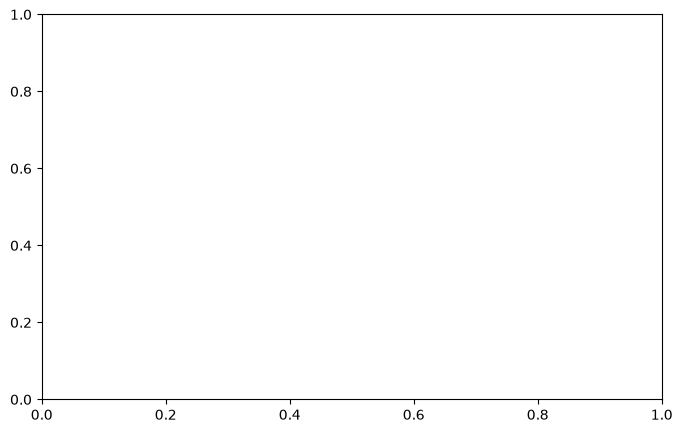

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = (
    make_pipeline(SesonalFeatureSelector(), RandomForestRegressor(max_features = 0.333, random_state=RANDOM_STATE, n_jobs=-1, bootstrap = True)),
    {
        "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
        "randomforestregressor__max_features": [0.2, 0.333, 0.5, 0.75, 1.0],
        "randomforestregressor__min_samples_split": [2, 5, 10],
        "randomforestregressor__max_samples": [0.5, 0.75, 0.9, 1.0],
    },
)

result_rf = evaluate_model(rf, X, y, y_bin, groups, outer_cv, inner_cv)
display(result_rf)

# todo: max_features 0.3333 affects model variance in rf graphs

## **Elastic Net regression**<a id="elastic-net"></a>

Elastic Net regression model is a Linear regression model with included additional regularization to minimalize model complexity and avoid overfitting. Elastic Net includes both the L1-norm and L2-norm, combining the feature selection capabilities of LASSO regression and the shared weights of the Ridge regression algorithm. This algorithm allowes for flexibilility with choosing thich regulrization should be more penalized with its hyperparameters.

#### Advantages:
- flexibilility with regularization techniques 
- possible feature selection to shink model complexity
- 

#### Disadvantages:
- 
- 
- 

#### Hyperparameters to tune:
- **`alpha`**: the regulariztion parameter which controls the amount of regularization on the model (can go from 0 to +∞, where 0 is no regularization so a standard linear regression and +∞ sets the beta parameters to 0 so maximal regularization possible)
- **`l1_ratio`**: the importance of the L1 penalty or the mixinig parameter, the value can be in range from 0 to 1


In [ ]:
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler

elastic_net = (
        make_pipeline(SesonalFeatureSelector(), StandardScaler(), ElasticNet(random_state = RANDOM_STATE)),
        {
            "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
            "elasticnet__alpha": [0, 0.5, 1, 2, 5, 10, 50, 100, 500, 1000, 5000],
            "elasticnet__l1_ratio": [0.01, 0.1, 0.25, 0.35, 0.5, 0.75, 0.9, 0.95, 1.0]
        },
)

result_elastic_net = evaluate_model(elastic_net, X, y, y_bin, groups, outer_cv, inner_cv)
display(result_elastic_net)

## **Discussion of results**<a id="discussion"></a>